In [65]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Demonstrator 1 - Diffusive and dispersive properties of the advection schemes

## Aim of Tutorial

The aim of this tutorial is to give the readers an opportunity to run the salt block simulation using the different advection schemes. Here we choose to use the transport of a block of salt to demonstrate how the diffusive and dispersive properties of the advection scheme impact the outcome of a simulation.

To run this demonstrator you must have followed Tutorial 1 beforehand.

## Dispersive scheme 

### Running the simulation

An example of a dispersive scheme in NEMO 5.0 is the CENtred advection scheme (CEN).
To run a CEN2 simulation, we need to change ```ln_traadv_cen``` from ```.false.``` to ```.true.``` and ```nn_cen_h``` and ```nn_cen_v``` from ```4``` to ```2``` in the namelist.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [67]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_cen2_all_grid.nc

chmod -R a+x /"$DIR"/demo1_cfg/

bash /"$DIR"/demo1_cfg/saltblock_cfg.sh "$DIR"
bash /"$DIR"/demo1_cfg/cen2_cfg.sh "$DIR"


+ set -v
set -u #Turn on error if usinf unset variables
+ set -u


if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg ']'
+ echo 'Erreur : fichier introuvable : net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg'
+ exit 1
+ set -v
set -u #Turn on error if using unset variables
+ set -u

if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP

fi
+ '[' '!' -f /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg ']'



sed -i.bak \
-e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen	=	.true.	!/' \
-e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF	=	.false.	!/' \
-e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct	=	.false.	!/' \
-e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus	=	.false.	!/' \
-e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs	=	.false.	!/' \
-e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck	=	.false.	!/' \
-e 's/nn_cen_h.*=.*\!/nn_cen_h	=	2		!/' \
-e 's/nn_cen_v.*=.*\!/nn_cen_v  =       2		!/' \
-e "s/cn_exp.*=.*'.*'/cn_exp =	'CANAL_saltblock_cen2'	/" \
-e 's/ln_traldf_OFF.*=.*\!/ln_traldf_OFF        =       .true. !/' \
-e 's/ln_traldf_lap.*=.*\!/ln_traldf_lap        =       .false. !/' \
-e 's/ln_traldf_blp.*=.*\!/ln_traldf_blp        =       .false. !/' \
"$SRC"
+ sed -i.bak -e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen	=	.true.	!/' -e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF	=	.false.	!/' -e 's/ln_traadv_fct.*=.*\!/ln_traadv_

Erreur : fichier introuvable : net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg



diff "$SRC" "$SRC.bak"
+ diff /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg.bak

sh /"$DIR"/run_nemo.sh && echo Run CANAL_saltblock_cen2_all_grid.nc completed
+ sh /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/run_nemo.sh


57c57
<    cn_exp =	'CANAL_saltblock_cen2'			!            	            	                  		!	 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'		!            	            	                  		!	 !  experience name

Everything looks good



+ echo Run CANAL_saltblock_cen2_all_grid.nc completed


Run CANAL_saltblock_cen2_all_grid.nc completed


```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .true. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .false. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .false.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_cen2``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

### Analysis of the outcome

In [ ]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = 'ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/'


cen2 = xr.open_dataset(rep+'CANAL_saltblock_cen2_all_grid.nc')
cen2

<xarray.Dataset> Size: 31MB
Dimensions:               (y_grid_T: 101, x_grid_T: 87, deptht: 2,
                           axis_nbounds: 2, y_grid_F: 101, x_grid_F: 87,
                           y_grid_U: 101, x_grid_U: 87, depthu: 2,
                           y_grid_V: 101, x_grid_V: 87, depthv: 2,
                           time_counter: 80)
Coordinates: (12/14)
    nav_lat_grid_T        (y_grid_T, x_grid_T) float32 35kB ...
    nav_lon_grid_T        (y_grid_T, x_grid_T) float32 35kB ...
  * deptht                (deptht) float32 8B 500.0 1.5e+03
    nav_lat_grid_F        (y_grid_F, x_grid_F) float32 35kB ...
    nav_lon_grid_F        (y_grid_F, x_grid_F) float32 35kB ...
    nav_lat_grid_U        (y_grid_U, x_grid_U) float32 35kB ...
    ...                    ...
    nav_lat_grid_V        (y_grid_V, x_grid_V) float32 35kB ...
    nav_lon_grid_V        (y_grid_V, x_grid_V) float32 35kB ...
  * depthv                (depthv) float32 8B 500.0 1.5e+03
    time_instant          (time_counter) object 640B ...
  * time_counter          (time_counter) object 640B 0001-01-01 12:00:00 ... ...
    time_centered         (time_counter) object 640B ...
Dimensions without coordinates: y_grid_T, x_grid_T, axis_nbounds, y_grid_F,
                                x_grid_F, y_grid_U, x_grid_U, y_grid_V, x_grid_V
Data variables: (12/14)
    deptht_bounds         (deptht, axis_nbounds) float32 16B ...
    depthu_bounds         (depthu, axis_nbounds) float32 16B ...
    depthv_bounds         (depthv, axis_nbounds) float32 16B ...
    time_instant_bounds   (time_counter, axis_nbounds) object 1kB ...
    time_counter_bounds   (time_counter, axis_nbounds) object 1kB ...
    time_centered_bounds  (time_counter, axis_nbounds) object 1kB ...
    ...                    ...
    sssgrad               (time_counter, y_grid_T, x_grid_T) float32 3MB ...
    ssrelvor              (time_counter, y_grid_F, x_grid_F) float32 3MB ...
    saltc                 (time_counter, y_grid_T, x_grid_T) float32 3MB ...
    salt2c                (time_counter, y_grid_T, x_grid_T) float32 3MB ...
    uoce                  (time_counter, depthu, y_grid_U, x_grid_U) float32 6MB ...
    voce                  (time_counter, depthv, y_grid_V, x_grid_V) float32 6MB ...
Attributes:
    name:         CANAL_saltblock_cen2_all_grid
    description:  ocean T/U/V grid variables
    title:        ocean T/U/V grid variables
    Conventions:  CF-1.6
    timeStamp:    2026-Oct-02 13:16:55 GMT
    uuid:         54d2f013-b4ae-4655-8ff7-84150112f857

In [ ]:
def show_t (t_list, param, title, file, rep=rep):
    " show_t displays a field from an xarray at given timesteps"
    "t_list : list of the timesteps displayed"
    "param : field displayed"
    "title : title of the figure"
    "file : name of the .nc array"
    "rep : path to the file (directory mentioned above by default)"

    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(10, 6))
    for i, t in enumerate(t_list) : 
        # We select and show the desired field at different timesteps and at sea surface, excluding the walls
        data = dataset[param].isel(time_counter = t, deptht = 0)[1:-1, :]
        im = axes[i].imshow(data, origin='lower', cmap='coolwarm')
        axes[i].set_title(f'{title} at (t={t+1} days)')
        axes[i].set_xlabel('x')
        axes[i].set_ylabel('y')
        fig.colorbar(im, ax=axes[i])
    plt.show()
    dataset.close()
    

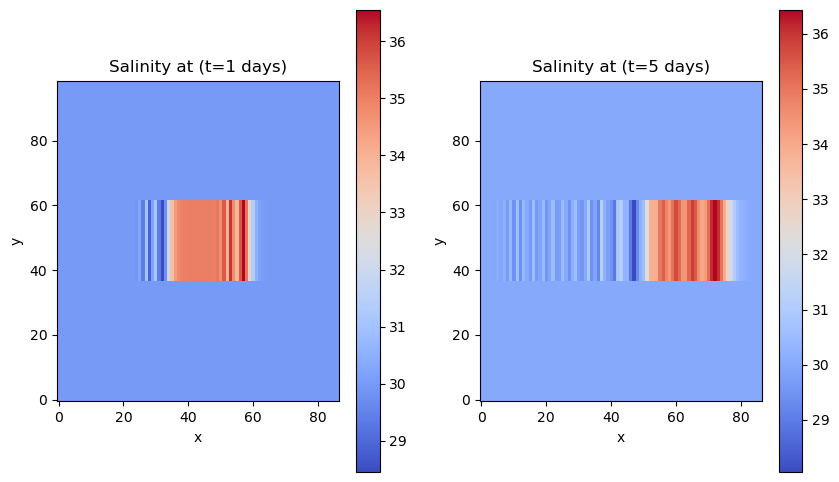

In [ ]:
show_t([0,4], 'soce', 'Salinity', 'CANAL_saltblock_cen2_all_grid.nc')

A dispersive scheme such as CEN2 causes different frequency components of a wave to travel at incorrect and varying speeds, creating spurious wiggles or phase shifts. The oscillations of values of the salinity tracer you should see around the edges of the block are symptomatic of the incorrect propagation occuring in a dispersive scheme.

To better visualize the oscillations of the signal let us trace the salinity of one fixed point in space through time.

Text(0, 0.5, 'Salinity')

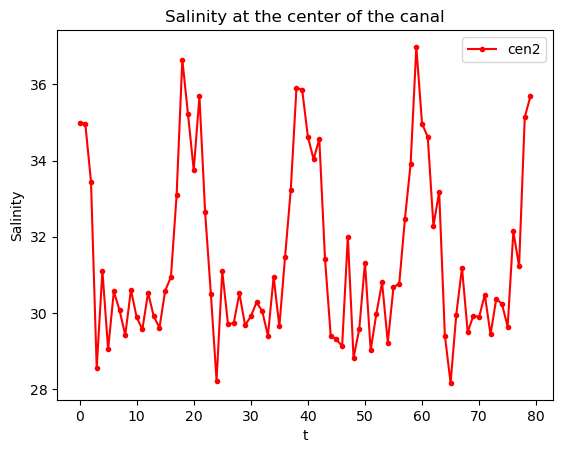

In [145]:

dataset = cen2['soce']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

data = dataset.isel(x_grid_T = xmid, y_grid_T = ymid, deptht=0) 
dep = np.arange(data.shape[0])
plt.plot(dep, data, 'r.-', label = 'cen2')


plt.legend()
plt.title(f"Salinity at the center of the canal")
plt.xlabel('t')
plt.ylabel('Salinity')
    


You should see oscillations near discontinuities. These represent the different frequency components of the square wave traveling at incorrect and varying speeds

In [96]:
def side_lobes(t_list, param, title, file, mode, rep=rep):
    " show_t displays a field from an xarray at given timesteps"
    "t_list : list of the timesteps displayed"
    "param : field displayed"
    "title : title of the figure"
    "file : name of the .nc array"
    "rep : path to the file (directory mentioned above by default)"

    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(15, 6))
    for i, t in enumerate(t_list) : 
        # We select and show the side lobes of the desired field at different timesteps and at sea surface, excluding the walls
        data = dataset[param].isel(time_counter = t, deptht = 0)[1:-1, :]
        # Creation of a mask to highlight the side-lobes
        mask0_under = (data < 30)
        mask0_over = (data > 35)

        if mode == 'binary': 
            side_lobes = mask0_over | mask0_under
            im = axes[i].imshow(side_lobes, origin='lower', cmap= ListedColormap(['blue', 'yellow']))
            axes[i].set_title(f'Placement of the side lobes of {title} at time {t+1}')
            axes[i].set_xlabel('x')
            axes[i].set_ylabel('y')
            fig.colorbar(im, ax=axes[i])
        elif mode == 'magnitude': 
            under = data*mask0_under
            over = data*mask0_over

            under = abs(under-30)
            under = under*mask0_under

            over = abs(over-35)
            over = over*mask0_over

            side_lobes = over + under
            min_ = side_lobes.min()
            max_ = side_lobes.max()
            im = axes[i].imshow(side_lobes, origin='lower', cmap='YlOrRd', vmin = min_, vmax = max_)
            axes[i].set_title(f'Magnitude of the side lobes of {title} at time {t+1}')
            axes[i].set_xlabel('x')
            axes[i].set_ylabel('y')
            fig.colorbar(im, ax=axes[i])
        else : 
            print(f"{mode} mode does not exist")

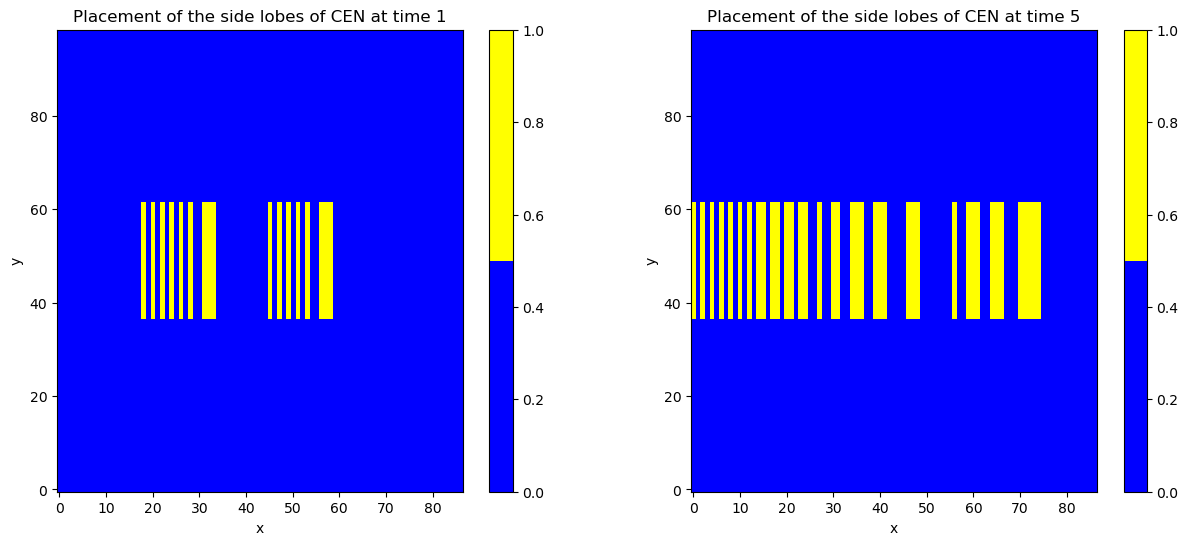

In [97]:
side_lobes([0, 4], 'soce', 'CEN', 'CANAL_saltblock_cen2_all_grid.nc', rep=rep, mode = 'binary')

A consequence of these oscillations due to discontinuous data is the Gibbs Phenomenon where high-order linear schemes attempting to resolve a sharp step will always produce an overshoot/undershoot 
near the discontinuity if they lack sufficient numerical diffusion to damp them out.

Areas where overshoot/undershoot are produced should appear in yellow.

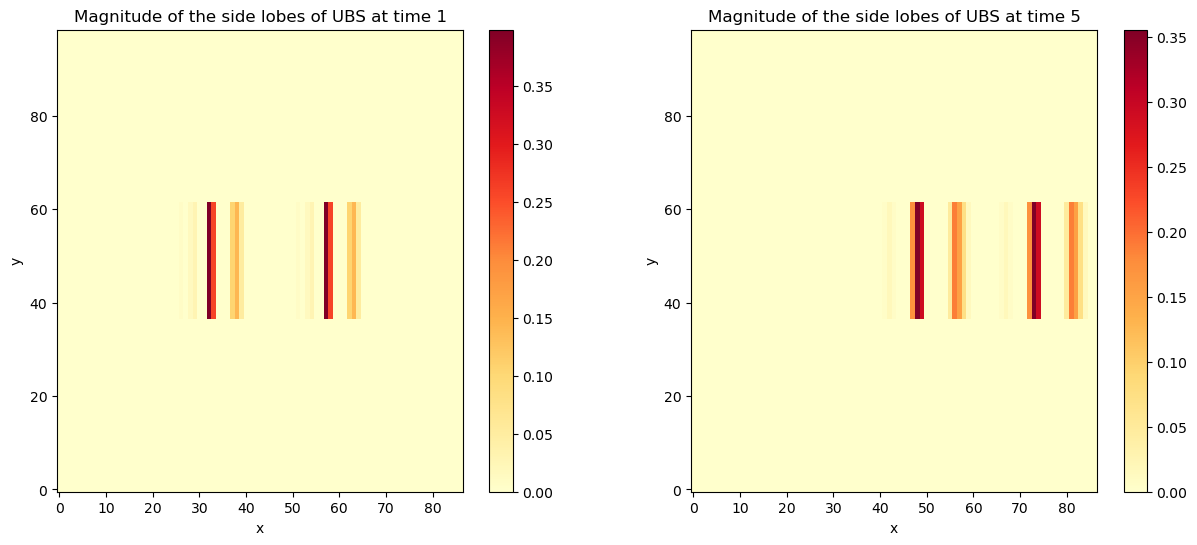

In [98]:
side_lobes([0, 4], 'soce', 'UBS', 'CANAL_saltblock_ubs_all_grid.nc', rep=rep, mode = 'magnitude')

Text(0, 0.5, 'Salinity gradient magnitude')

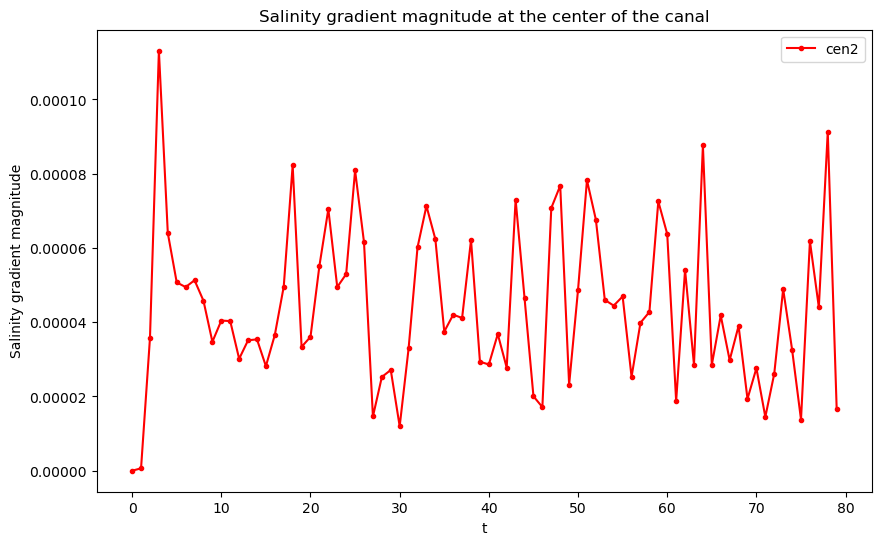

In [ ]:
fig_grad, axes_grad = plt.subplots(1, 1, figsize=(10, 6))

dataset = cen2['sssgrad']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

grad_cen2 = dataset.isel(x_grid_T = xmid, y_grid_T = ymid)
dep = np.arange(grad_cen2.shape[0])
axes_grad.plot(dep,  grad_cen2, 'r.-', label = 'cen2')


plt.legend()
plt.title(f"Salinity gradient magnitude at the center of the canal")
plt.xlabel('t')
plt.ylabel('Salinity gradient magnitude')


We do not see the periodic peaks that represent the front and the back of the square because the CEN scheme distorted the shape of the square. 

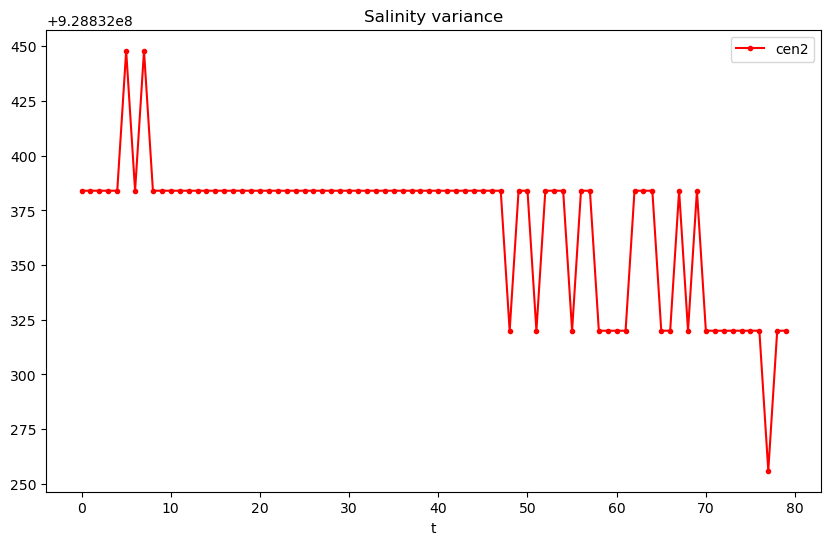

In [147]:
fig_salt2c, axes_salt2c = plt.subplots(1, 1, figsize=(10, 6))

dataset = cen2['salt2c']


s2c = dataset.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, 'r.-', label = 'cen2')

axes_salt2c.set_title("Salinity variance")
axes_salt2c.set_xlabel('t')


axes_salt2c.legend()

An advantage of the dispersive is that the tracer variance is conserved through time.

In [ ]:
cen2.close()

## Diffusive scheme 

### Running the simulation

An example of a diffusive scheme in NEMO 5.0 is the Upstream Biased Scheme (UBS).
To run a UBS simulation, we need to change ```ln_traadv_ubs``` from ```.false.``` to ```.true.``` in the namelist and set ```nn_ubs_v``` to ```2```.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [68]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_ubs_all_grid.nc

chmod -R a+x /"$DIR"/demo1_cfg/


bash /"$DIR"/demo1_cfg/saltblock_cfg.sh "$DIR"
bash /"$DIR"/demo1_cfg/ubs_cfg.sh "$DIR"


+ set -v
set -u #Turn on error if usinf unset variables
+ set -u


if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg ']'


SED_EXPR=(
-e 's/rn_domszx.*=.*\!/rn_domszx	=	864.	!/'
-e 's/rn_domszy.*=.*\!/rn_domszy	=	1000.	!/'
-e 's/rn_domszz.*=.*\!/rn_domszz	=	1000.  !/'
-e 's/rn_dx.*=.*\!/rn_dx	=	10.	!/'
-e 's/rn_dy.*=.*\!/rn_dy	=	10.  !/'
-e 's/rn_dz.*=.*\!/rn_dz	=	1000.  !/'
-e 's/rn_0xratio.*=.*\!/rn_0xratio	=	0.5  !/'
-e 's/rn_0yratio.*=.*\!/rn_0yratio	=	0.5  !/'
-e 's/nn_fcase.*=.*\!/nn_fcase	=	0  !/'
-e 's/rn_ppgphi

rn_salszx, rn_salszy already in the file, insertion ignored.





diff "$SRC.bak" "$SRC"
+ diff /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg.bak /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg

#./run_nemo.sh


set +x #Turn off debug
+ set +x
set +v #Turn off Print shell input lines
+ set -v
set -u #Turn on error if using unset variables
+ set -u

if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg ']'




sed -i.bak \
-e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .true.  !/' \
-e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .false. !/' \
-e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .false. !/' \
-e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/' \
-e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .false. !/' \
-e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/' \
-e 's/nn_ubs_v.*=.*\!/nn_ubs_v  =       2               !/' \
-e "s/cn_exp.*=.*'.*'/cn_exp =  'CANAL_saltblock_ubs'      /" \
-e 's/ln_traldf_OFF.*=.*\!/ln_traldf_OFF        =       .true. !/' \
-e 's/ln_traldf_lap.*=.*\!/ln_traldf_lap        =       .false. !/' \
-e 's/ln_traldf_blp.*=.*\!/ln_traldf_blp        =       .false. !/' \
"$SRC"
+ sed -i.bak -e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .true.  !/' -e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .false. !/' -e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .false. !/' -e 's/

19,29c19,29
<    rn_domszx      =      	2000.    !  x horizontal size         [km]
<    rn_domszy      =       1000.   !  y horizontal size         [km]
<    rn_domszz      =       1000.  !  z vertical size            [m]
<    rn_dx      =       10.     !  x horizontal resolution   [km]
<    rn_dy      =       10.  !  y horizontal resolution   [km]
<    rn_dz      =       1000.  !  z vertical resolution      [m]
<    rn_0xratio    =       0.5  !  x-domain ratio of the 0
<    rn_0yratio    =       0.5  !  y-domain ratio of the 0
<    nn_fcase        =       0  !  F computation (0:f0, 1:Beta, 2:real)
<    rn_ppgphi0    =       38.5  !  Reference latitude      [degrees]
<    rn_u10    =       0.  !  10m wind speed              [m/s]
---
>    rn_domszx	=	864.	!  x horizontal size         [km]
>    rn_domszy	=	1000.	!  y horizontal size         [km]
>    rn_domszz	=	1000.  !  z vertical size            [m]
>    rn_dx	=	10.	!  x horizontal resolution   [km]
>    rn_dy	=	10.  !  y horizontal 


diff "$SRC" "$SRC.bak"
+ diff /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg.bak

sh /"$DIR"/run_nemo.sh && echo Run CANAL_saltblock_ubs_all_grid.nc completed
+ sh //net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/run_nemo.sh


57c57
<    cn_exp =  'CANAL_saltblock_ubs'      	!			!            	            	                  		!	 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'	!			!            	            	                  		!	 !  experience name
165,166c165,166
<    ln_traadv_OFF        =       .false. !  No tracer advection
<    ln_traadv_cen        =       .false. !  2nd order centered scheme
---
>    ln_traadv_OFF	=	.false.	!  No tracer advection
>    ln_traadv_cen	=	.true.	!  2nd order centered scheme
169c169
<    ln_traadv_fct        =       .false. !  FCT scheme
---
>    ln_traadv_fct	=	.false.	!  FCT scheme
172c172
<    ln_traadv_mus        =       .false. !  MUSCL scheme
---
>    ln_traadv_mus	=	.false.	!  MUSCL scheme
174c174
<    ln_traadv_ubs        =       .true.  !  UBS scheme
---
>    ln_traadv_ubs	=	.false.	!  UBS scheme
176c176
<    ln_traadv_qck        =       .false. !  QUICKEST scheme
---
>    ln_traadv_qck	=	.false.	!  QUICKEST scheme

Everything looks good



+ echo Run CANAL_saltblock_ubs_all_grid.nc completed








Run CANAL_saltblock_ubs_all_grid.nc completed


```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .false. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .false. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .true.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_ubs``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

### Analysis of the outcome

In [ ]:
#Open the simulation using the xr library

ubs = xr.open_dataset(rep+'CANAL_saltblock_ubs_all_grid.nc')
ubs

<xarray.Dataset> Size: 31MB
Dimensions:               (y_grid_T: 101, x_grid_T: 87, deptht: 2,
                           axis_nbounds: 2, y_grid_F: 101, x_grid_F: 87,
                           y_grid_U: 101, x_grid_U: 87, depthu: 2,
                           y_grid_V: 101, x_grid_V: 87, depthv: 2,
                           time_counter: 80)
Coordinates: (12/14)
    nav_lat_grid_T        (y_grid_T, x_grid_T) float32 35kB ...
    nav_lon_grid_T        (y_grid_T, x_grid_T) float32 35kB ...
  * deptht                (deptht) float32 8B 500.0 1.5e+03
    nav_lat_grid_F        (y_grid_F, x_grid_F) float32 35kB ...
    nav_lon_grid_F        (y_grid_F, x_grid_F) float32 35kB ...
    nav_lat_grid_U        (y_grid_U, x_grid_U) float32 35kB ...
    ...                    ...
    nav_lat_grid_V        (y_grid_V, x_grid_V) float32 35kB ...
    nav_lon_grid_V        (y_grid_V, x_grid_V) float32 35kB ...
  * depthv                (depthv) float32 8B 500.0 1.5e+03
    time_instant          (time_counter) object 640B ...
  * time_counter          (time_counter) object 640B 0001-01-01 12:00:00 ... ...
    time_centered         (time_counter) object 640B ...
Dimensions without coordinates: y_grid_T, x_grid_T, axis_nbounds, y_grid_F,
                                x_grid_F, y_grid_U, x_grid_U, y_grid_V, x_grid_V
Data variables: (12/14)
    deptht_bounds         (deptht, axis_nbounds) float32 16B ...
    depthu_bounds         (depthu, axis_nbounds) float32 16B ...
    depthv_bounds         (depthv, axis_nbounds) float32 16B ...
    time_instant_bounds   (time_counter, axis_nbounds) object 1kB ...
    time_counter_bounds   (time_counter, axis_nbounds) object 1kB ...
    time_centered_bounds  (time_counter, axis_nbounds) object 1kB ...
    ...                    ...
    sssgrad               (time_counter, y_grid_T, x_grid_T) float32 3MB ...
    ssrelvor              (time_counter, y_grid_F, x_grid_F) float32 3MB ...
    saltc                 (time_counter, y_grid_T, x_grid_T) float32 3MB ...
    salt2c                (time_counter, y_grid_T, x_grid_T) float32 3MB ...
    uoce                  (time_counter, depthu, y_grid_U, x_grid_U) float32 6MB ...
    voce                  (time_counter, depthv, y_grid_V, x_grid_V) float32 6MB ...
Attributes:
    name:         CANAL_saltblock_ubs_all_grid
    description:  ocean T/U/V grid variables
    title:        ocean T/U/V grid variables
    Conventions:  CF-1.6
    timeStamp:    2026-Oct-02 13:17:29 GMT
    uuid:         ac3a7ba7-b386-40d5-b71f-e3688192f29b

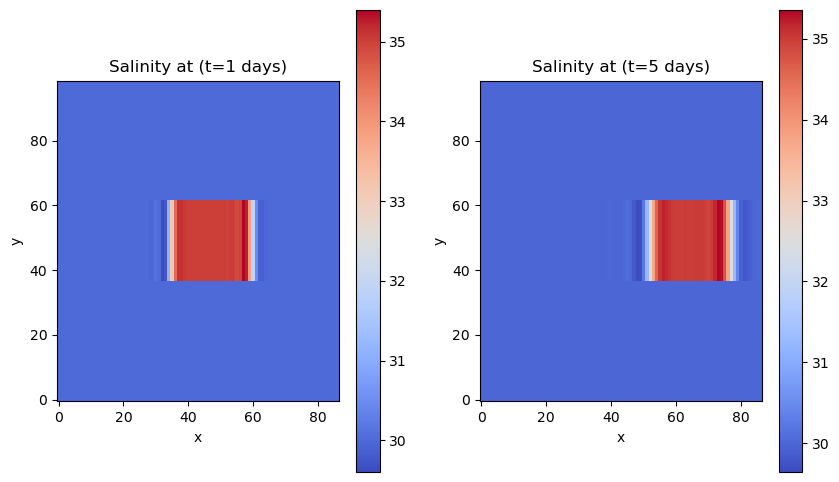

In [ ]:
show_t([0,4], 'soce', 'Salinity', 'CANAL_saltblock_ubs_all_grid.nc')

UBS is a diffusive scheme, it acts like artificial viscosity,  it should cause peaks to flatten and sharp edges to blur. 

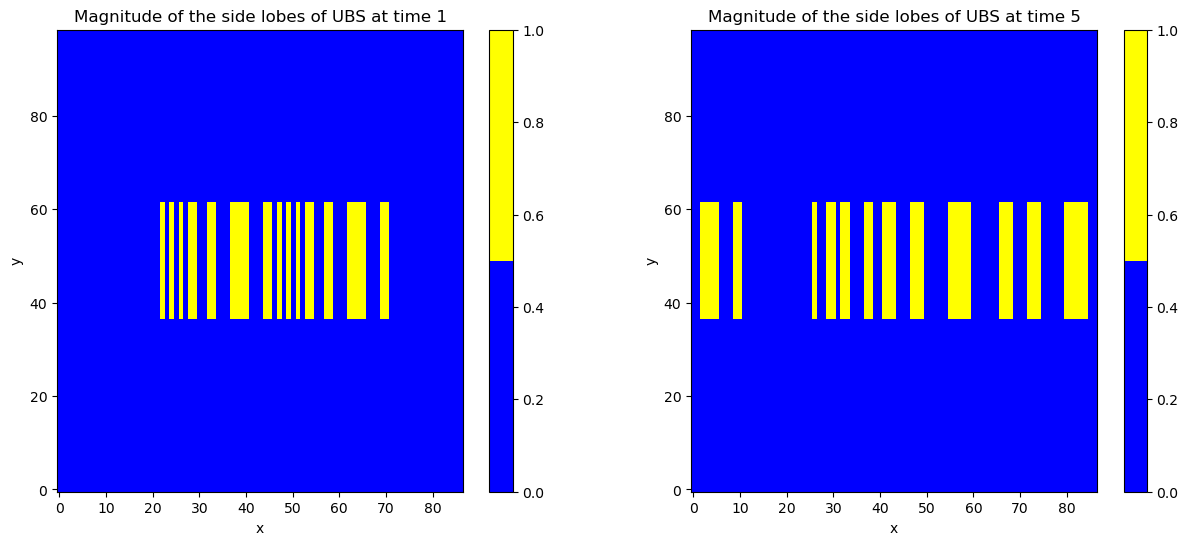

In [91]:
side_lobes([0, 4], 'soce', 'UBS', 'CANAL_saltblock_ubs_all_grid.nc', rep=rep, mode = 'binary')

The UBS scheme is not positive either, meaning that false extrema (highlighted in yellow above) are permitted, but the amplitude of such are significantly reduced compared to CEN2 as shown below.

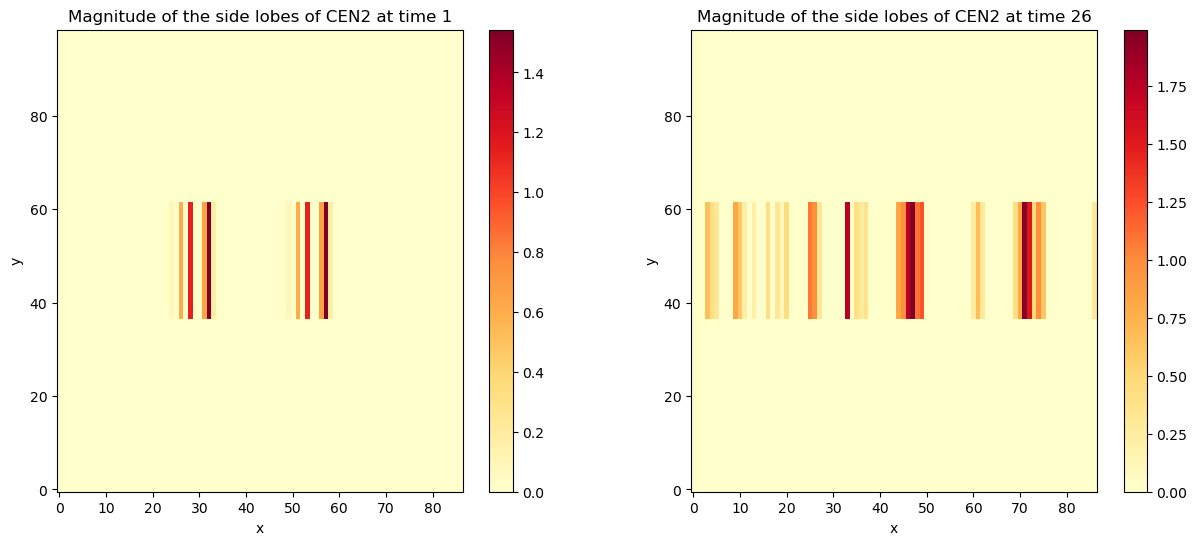

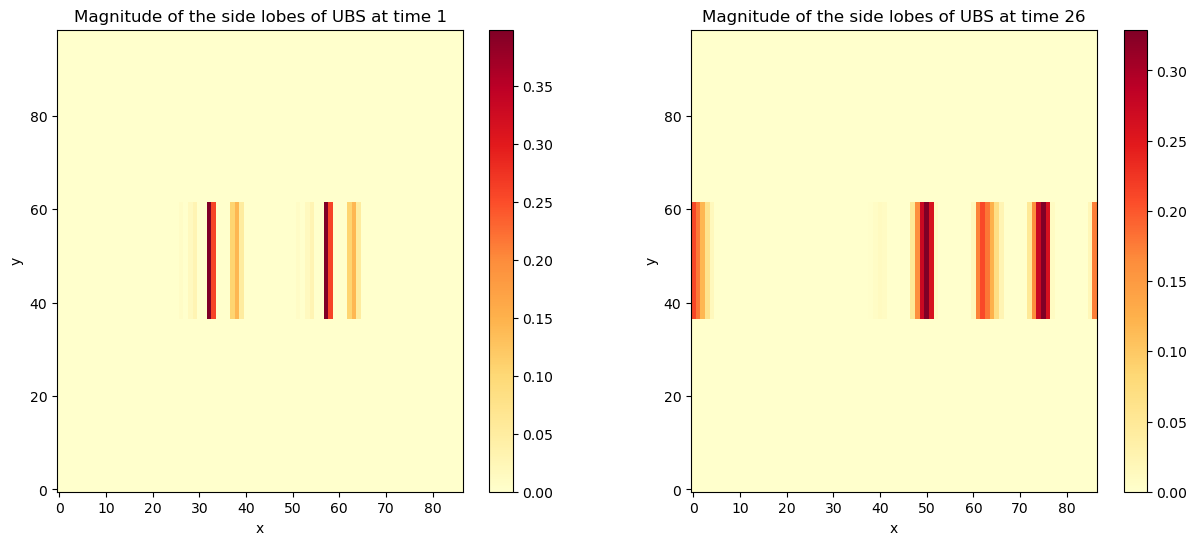

In [92]:
side_lobes([0, 25], 'soce', 'CEN2', 'CANAL_saltblock_cen2_all_grid.nc', mode = 'magnitude', rep=rep)
side_lobes([0, 25], 'soce', 'UBS', 'CANAL_saltblock_ubs_all_grid.nc', mode = 'magnitude', rep=rep)


The UBS scheme is not positive either, meaning that false extrema (highlighted in yellow above) are permitted, but the amplitude of such are significantly reduced compared to CEN2 as shown below.

Text(0, 0.5, 'Salinity')

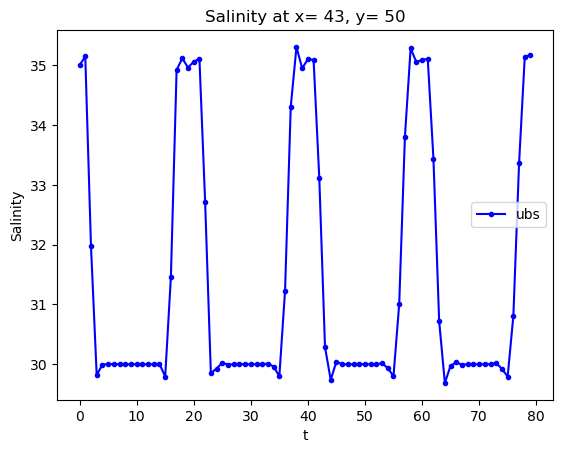

In [93]:
dataset = ubs['soce']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

data = dataset.isel(x_grid_T = xmid, y_grid_T = ymid, deptht=0) 
dep = np.arange(data.shape[0])
plt.plot(dep, data, 'b.-', label = 'ubs')


plt.legend()
plt.title(f"Salinity at x= {xmid}, y= {ymid}")
plt.xlabel('t')
plt.ylabel('Salinity')
    


The artefacts of the dispersive component are the oscillations near the sharp edges, the drops below 30 and the values over 35. The artecfacts of the diffusive components are the peaks and sharp edges being smoothed out. As the effect of the dispersive component counters the effect of the diffusive component (the oscillations produced by the the dispersive component are smoothed out by the diffusive component), it is quite difficult to make a diagnosis out of the figure other than the overshoot/undershoot.

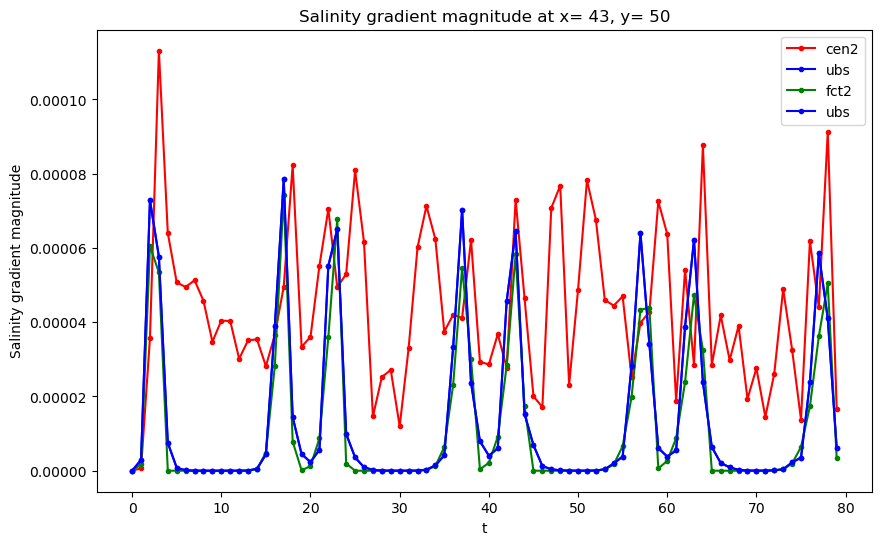

In [94]:
dataset = ubs['sssgrad']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

grad_ubs = dataset.isel(x_grid_T = xmid, y_grid_T = ymid)
dep = np.arange(grad_ubs.shape[0])
axes_grad.plot(dep,  grad_ubs, 'b.-', label = 'ubs')


axes_grad.legend()
axes_grad.set_title(f"Salinity gradient magnitude at x= {xmid}, y= {ymid}")
axes_grad.set_xlabel('t')
axes_grad.set_ylabel('Salinity gradient magnitude')

fig_grad

The amplitude of high magnitude gradients should decay (dampening effect) compared to the CEN2 graph.

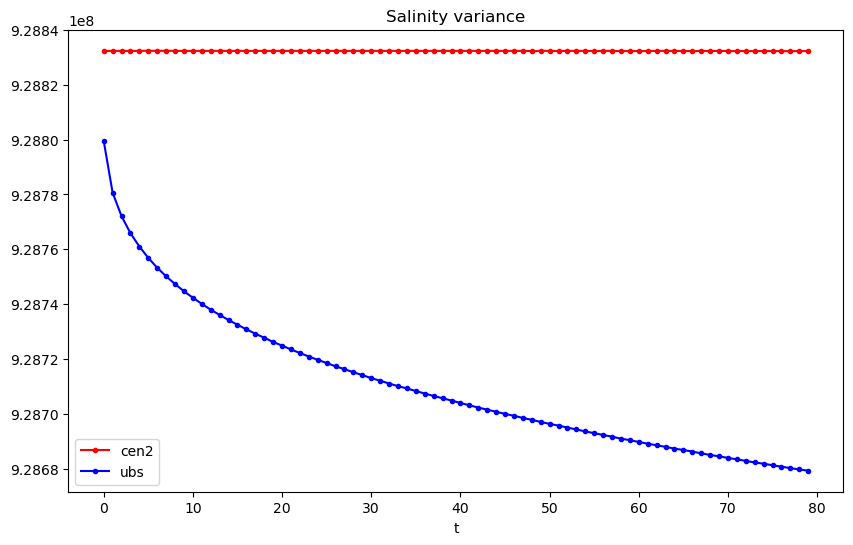

In [ ]:
dataset = ubs['salt2c']


s2c_ubs = dataset.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c_ubs.shape[0])
axes_salt2c.plot(dep,  s2c_ubs, 'b.-', label = 'ubs')

axes_salt2c.set_title("Salinity variance")
axes_salt2c.set_xlabel('t')

axes_salt2c.legend()

fig_salt2c

Contrary to dispersive schemes, diffusive schemes are non-positive, the tracer variance should systematically decrease (dissipation).

In [ ]:
ubs.close()

## Corrected scheme 

### Running the simulation

An example of a corrected scheme in NEMO 5.0 is the Flux Corrected Transport scheme (FCT).
To run a FCT simulation, we need to change ```ln_traadv_fct``` from ```.false.``` to ```.true.``` and the ```nn_fct_h``` and ```nn_fct_v``` from ```4``` to ```2``` in the namelist.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [ ]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_fct2_all_grid.nc

chmod -R a+x /"$DIR"/demo1_cfg/


bash /"$DIR"/demo1_cfg/saltblock_cfg.sh "$DIR"
bash /"$DIR"/demo1_cfg/fct2_cfg.sh "$DIR"


+ set -v
set -u #Turn on error if usinf unset variables
+ set -u


if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg ']'


SED_EXPR=(
-e 's/rn_domszx.*=.*\!/rn_domszx	=	864.	!/'
-e 's/rn_domszy.*=.*\!/rn_domszy	=	1000.	!/'
-e 's/rn_domszz.*=.*\!/rn_domszz	=	1000.  !/'
-e 's/rn_dx.*=.*\!/rn_dx	=	10.	!/'
-e 's/rn_dy.*=.*\!/rn_dy	=	10.  !/'
-e 's/rn_dz.*=.*\!/rn_dz	=	1000.  !/'
-e 's/rn_0xratio.*=.*\!/rn_0xratio	=	0.5  !/'
-e 's/rn_0yratio.*=.*\!/rn_0yratio	=	0.5  !/'
-e 's/nn_fcase.*=.*\!/nn_fcase	=	0  !/'
-e 's/rn_ppgphi

   rn_salszx = 500.        ! width of the saltblock [km]\
   rn_salszy = 500.        ! height of the salt block [km]')
else
    echo "rn_salszx, rn_salszy already in the file, insertion ignored."
fi
+ grep -q rn_salszx /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg
+ echo 'rn_salszx, rn_salszy already in the file, insertion ignored.'

sed -i.bak "${SED_EXPR[@]}" "$SRC"
+ sed -i.bak -e 's/rn_domszx.*=.*\!/rn_domszx	=	864.	!/' -e 's/rn_domszy.*=.*\!/rn_domszy	=	1000.	!/' -e 's/rn_domszz.*=.*\!/rn_domszz	=	1000.  !/' -e 's/rn_dx.*=.*\!/rn_dx	=	10.	!/' -e 's/rn_dy.*=.*\!/rn_dy	=	10.  !/' -e 's/rn_dz.*=.*\!/rn_dz	=	1000.  !/' -e 's/rn_0xratio.*=.*\!/rn_0xratio	=	0.5  !/' -e 's/rn_0yratio.*=.*\!/rn_0yratio	=	0.5  !/' -e 's/nn_fcase.*=.*\!/nn_fcase	=	0  !/' -e 's/rn_ppgphi0.*=.*\!/rn_ppgphi0	=	38.5  !/' -e 's/rn_u10.*=.*\!/rn_u10	=	0.  !/' -e 's/rn_uzonal.*=.*\!/rn_uzonal	=	0.5  !/' -e 's/rn_ujetszx.*=.*\!/rn_ujetszx		=	864.  !/' -e 's/rn_uje

rn_salszx, rn_salszy already in the file, insertion ignored.





diff "$SRC.bak" "$SRC"
+ diff /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg.bak /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg

#./run_nemo.sh


set +x #Turn off debug
+ set +x
set +v #Turn off Print shell input lines
+ set -v
set -u #Turn on error if using unset variables
+ set -u

if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg ']'


sed -i.bak \
-e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .true.  !/

57c57
<    cn_exp =  'CANAL_saltblock_ubs'      	            	                  		!	 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'      	            	                  		!	 !  experience name



diff "$SRC" "$SRC.bak"
+ diff /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg.bak

sh /"$DIR"/run_nemo.sh && echo Run CANAL_saltblock_fct2_all_grid.nc completed
+ sh //net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/run_nemo.sh


57c57
<    cn_exp =  'CANAL_saltblock_fct2'            	            	                  		!	 !  experience name
---
>    cn_exp	=	'CANAL_saltblock'      	            	                  		!	 !  experience name
169c169
<    ln_traadv_fct        =       .true.  !  FCT scheme
---
>    ln_traadv_fct        =       .false. !  FCT scheme
174c174
<    ln_traadv_ubs        =       .false. !  UBS scheme
---
>    ln_traadv_ubs        =       .true.  !  UBS scheme

Everything looks good



+ echo Run CANAL_saltblock_fct2_all_grid.nc completed







Run CANAL_saltblock_fct2_all_grid.nc completed


```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .false. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .true. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .false.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_fct2``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

### Analysis of the outcome

In [ ]:
#Open the simulation using the xr library

fct2 = xr.open_dataset(rep+'CANAL_saltblock_fct2_all_grid.nc')
fct2

<xarray.Dataset> Size: 31MB
Dimensions:               (y_grid_T: 101, x_grid_T: 87, deptht: 2,
                           axis_nbounds: 2, y_grid_F: 101, x_grid_F: 87,
                           y_grid_U: 101, x_grid_U: 87, depthu: 2,
                           y_grid_V: 101, x_grid_V: 87, depthv: 2,
                           time_counter: 80)
Coordinates: (12/14)
    nav_lat_grid_T        (y_grid_T, x_grid_T) float32 35kB ...
    nav_lon_grid_T        (y_grid_T, x_grid_T) float32 35kB ...
  * deptht                (deptht) float32 8B 500.0 1.5e+03
    nav_lat_grid_F        (y_grid_F, x_grid_F) float32 35kB ...
    nav_lon_grid_F        (y_grid_F, x_grid_F) float32 35kB ...
    nav_lat_grid_U        (y_grid_U, x_grid_U) float32 35kB ...
    ...                    ...
    nav_lat_grid_V        (y_grid_V, x_grid_V) float32 35kB ...
    nav_lon_grid_V        (y_grid_V, x_grid_V) float32 35kB ...
  * depthv                (depthv) float32 8B 500.0 1.5e+03
    time_instant          (time_counter) object 640B ...
  * time_counter          (time_counter) object 640B 0001-01-01 12:00:00 ... ...
    time_centered         (time_counter) object 640B ...
Dimensions without coordinates: y_grid_T, x_grid_T, axis_nbounds, y_grid_F,
                                x_grid_F, y_grid_U, x_grid_U, y_grid_V, x_grid_V
Data variables: (12/14)
    deptht_bounds         (deptht, axis_nbounds) float32 16B ...
    depthu_bounds         (depthu, axis_nbounds) float32 16B ...
    depthv_bounds         (depthv, axis_nbounds) float32 16B ...
    time_instant_bounds   (time_counter, axis_nbounds) object 1kB ...
    time_counter_bounds   (time_counter, axis_nbounds) object 1kB ...
    time_centered_bounds  (time_counter, axis_nbounds) object 1kB ...
    ...                    ...
    sssgrad               (time_counter, y_grid_T, x_grid_T) float32 3MB ...
    ssrelvor              (time_counter, y_grid_F, x_grid_F) float32 3MB ...
    saltc                 (time_counter, y_grid_T, x_grid_T) float32 3MB ...
    salt2c                (time_counter, y_grid_T, x_grid_T) float32 3MB ...
    uoce                  (time_counter, depthu, y_grid_U, x_grid_U) float32 6MB ...
    voce                  (time_counter, depthv, y_grid_V, x_grid_V) float32 6MB ...
Attributes:
    name:         CANAL_saltblock_fct2_all_grid
    description:  ocean T/U/V grid variables
    title:        ocean T/U/V grid variables
    Conventions:  CF-1.6
    timeStamp:    2026-Oct-02 13:18:04 GMT
    uuid:         e40246ee-4a00-4074-9049-a7564a03c621

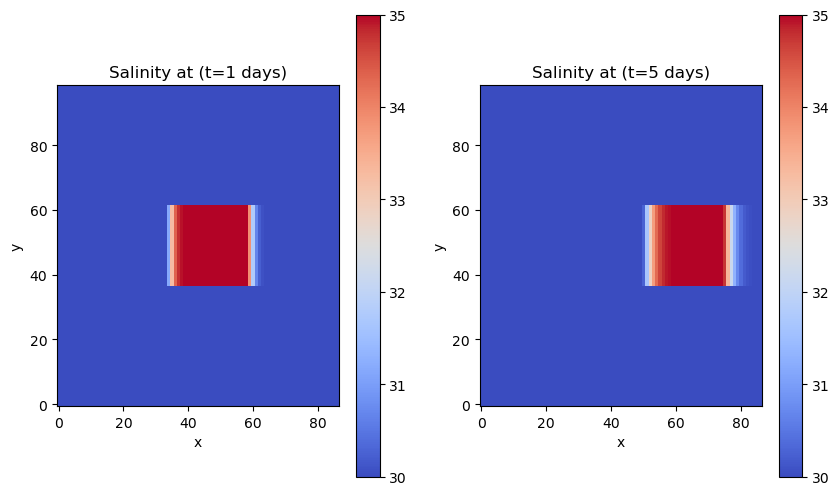

In [ ]:
show_t([0,4], 'soce', 'Salinity', 'CANAL_saltblock_fct2_all_grid.nc')

FCT2 is also a scheme where a dispersive scheme is combined with a diffusive scheme.

In [ ]:
t0 = 0
t1 = 4

fct2_t0 = xr.open_dataset(rep+'CANAL_saltblock_fct2_all_grid.nc').soce.isel(time_counter = t0, deptht = 0)[1:-1, :]
fct2_t1 = xr.open_dataset(rep+'CANAL_saltblock_fct2_all_grid.nc').soce.isel(time_counter = t1, deptht = 0)[1:-1, :]


In [ ]:
# Creation of a mask to highlight the side-lobes
mask0 = (fct2_t0 < 30)| (fct2_t0 > 35)
mask1 = (fct2_t1 < 30) | (fct2_t1 > 35)
# 35 was the initial value of the salt block and 30 the initial value of the background

print(f" There were values over 35 or under 30 at timestep t = {t0+1} : {bool(mask0.any())} or t = {t1+1} : {bool(mask1.any())}")


 There were values over 35 or under 30 at timestep t = 1 : False or t = 5 : False


The diffusive scheme is activated when a local extremum is produced and it is used to corrects the side lobe. That is why we should not see values over the maximum initial value of salinity or values under the mininum initial value of salinity.

Text(0, 0.5, 'Salinity')

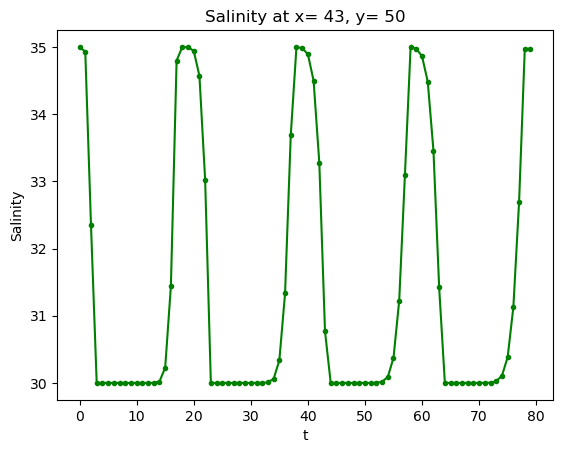

In [ ]:
dataset = fct2['soce']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

data = dataset.isel(x_grid_T = xmid, y_grid_T = ymid, deptht=0) 
dep = np.arange(data.shape[0])
plt.plot(dep, data, 'g.-')

plt.title(f"Salinity at x= {xmid}, y= {ymid}")
plt.xlabel('t')
plt.ylabel('Salinity')
    


Similarly to the UBS scheme, a "dampening", a flattening of the sharp peaks of the square wave should be seen. As the side lobes are automatically fully corrected as soon as they appear they cannot spread oscillations.

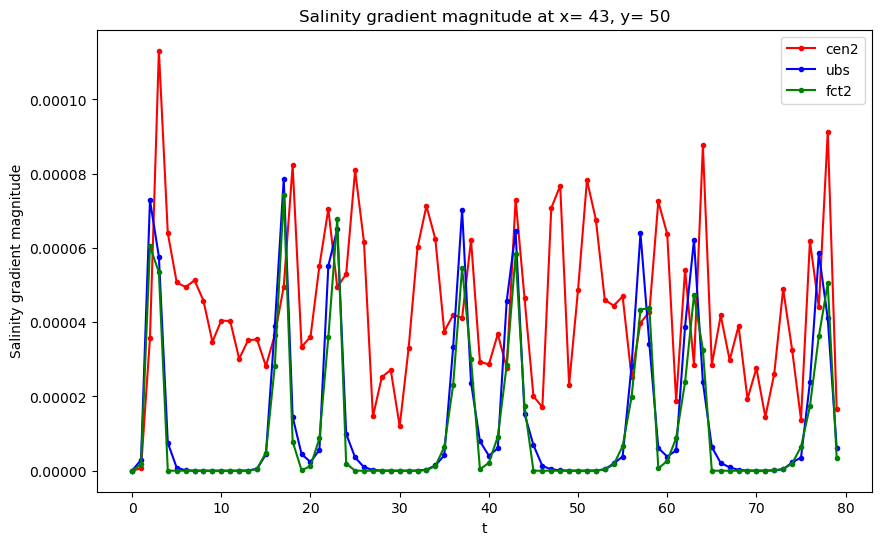

In [ ]:
dataset = fct2['sssgrad']
ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

grad_fct2 = dataset.isel(x_grid_T = xmid, y_grid_T = ymid)
dep = np.arange(grad_fct2.shape[0])
axes_grad.plot(dep,  grad_fct2, 'g.-', label = 'fct2')


axes_grad.legend()
axes_grad.set_title(f"Salinity gradient magnitude at x= {xmid}, y= {ymid}")
axes_grad.set_xlabel('t')
axes_grad.set_ylabel('Salinity gradient magnitude')
    
fig_grad

The amplitude of high magnitude gradients should decay due to the diffusive component of the scheme (dampening effect).

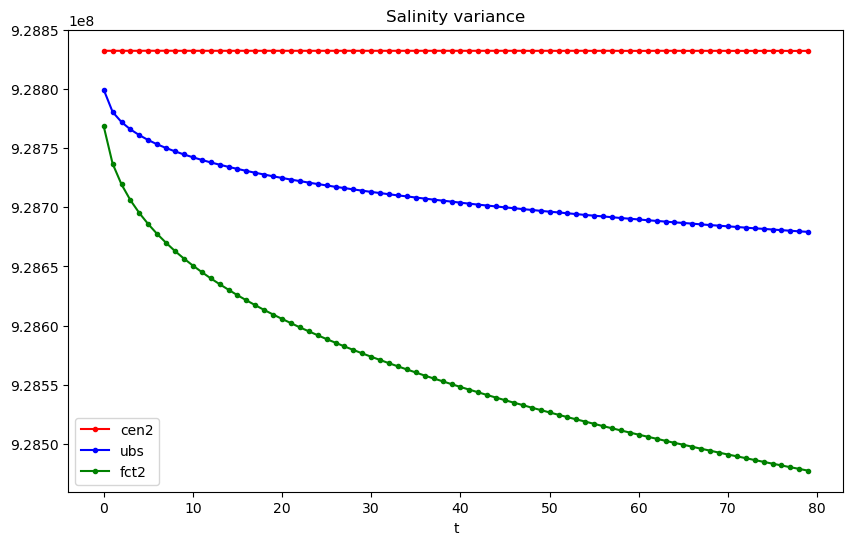

In [ ]:
dataset = fct2['salt2c']


s2c = dataset.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
axes_salt2c.plot(dep,  s2c, 'g.-', label = 'fct2')

axes_salt2c.set_title("Salinity variance")
axes_salt2c.set_xlabel('t')

axes_salt2c.legend()

fig_salt2c

Contrary to dispersive schemes, diffusive schemes are non-positive, the tracer variance should systematically decrease (dissipation). 

In [ ]:
fct2.close()